In [ ]:
# Install required packages (run in Colab or your environment)
# !pip install transformers datasets trl huggingface_hub trackio num2words==0.5.14

### Load Modules

In [2]:
import torch
import os
from transformers import AutoProcessor, AutoModelForImageTextToText, BitsAndBytesConfig
from transformers.image_utils import load_image
from peft import LoraConfig, get_peft_model

In [3]:
device = (
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available() else 'cpu'
)

### Load Dataset

In [4]:
from datasets import load_dataset
import matplotlib.pyplot as plt

train_dataset, eval_dataset = load_dataset("HuggingFaceM4/ChartQA", split=["train[:10%]", "val[:10%]"])
example = train_dataset[1]
image = load_image(example["image"])

print(example["query"])
print(example['label'][0])

How many values are below 40 in Unfavorable graph?
6


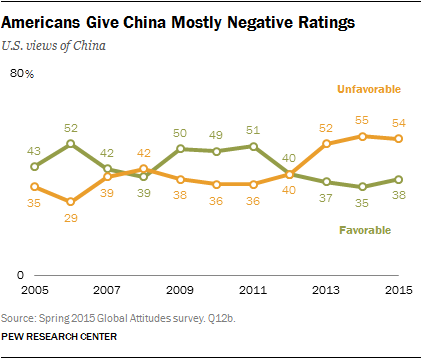

In [6]:
image

In [9]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": example["query"]}
        ]
    }
]

# Apply chat template
chat_prompt = processor.apply_chat_template(messages, add_generation_prompt=True)

print(chat_prompt)

<|im_start|>User:<image>How many values are below 40 in Unfavorable graph?<end_of_utterance>
Assistant:


In [31]:
# Run inference

# tokenize inputs
inputs = processor(images=[image], text=chat_prompt, return_tensors="pt").to(device)

with torch.inference_mode():
    output = model.generate(**inputs, max_new_tokens=200)


# trim the generated ids to remove the input ids
trimmed_generated_ids = [out_ids[len(in_ids):] for in_ids, out_ids in zip(inputs.input_ids, output)]

# Decode the output text
output_text = processor.batch_decode(
    trimmed_generated_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False
)
print(output_text[0])

 7.


#### Finetuning

In [5]:
# PREPARE DATASET

system_message = """You are a Vision Language Model specialized in interpreting visual data from chart images.
Your task is to analyze the provided chart image and respond to queries with concise answers, usually a single word, number, or short phrase.
The charts include a variety of types (e.g., line charts, bar charts) and contain colors, labels, and text.
Focus on delivering accurate, succinct answers based on the visual information. Avoid additional explanation unless absolutely necessary."""

# Format dataset
def format_data(sample):
    """Formats a single data sample for the VLM."""
    label = sample['label']
    if isinstance(label, list):
        label = label[0]

    question = sample['query']
    return {
        "images": [sample["image"]],
        "messages": [
            {
                "role": "system", 
                "content": [{"type": "text", "text": system_message}]},
            {
                "role": "user", 
                "content": [
                    {"type": "image"}, #, "image": sample["image"]}, 
                    {"type": "text", "text": question}
                ]
            },
            {
                "role": "assistant", 
                "content": [{"type": "text", "text": label}]
            }
        ]
    }

train_dataset = train_dataset.map(format_data)
eval_dataset = eval_dataset.map(format_data)

print(len(train_dataset))
print(len(eval_dataset))

2830
192


### Load model and processor

In [6]:
from peft import LoraConfig, get_peft_model

# configure lora
peft_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=['q_proj', 'v_proj'],
    task_type='CAUSAL_LM'
)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16
)

model_name = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"
model = AutoModelForImageTextToText.from_pretrained(
    model_name, 
    quantization_config=bnb_config,
    dtype=torch.float16).to(device)

processor = AutoProcessor.from_pretrained(model_name)

# Apply PEFT model adaptation
peft_model = get_peft_model(model, peft_config)

# Print trainable parameters
peft_model.print_trainable_parameters()


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

trainable params: 2,568,192 || all params: 2,249,353,072 || trainable%: 0.1142


In [ ]:
# Training configuration
from trl import SFTConfig, SFTTrainer

# configure training arguments
training_args = SFTConfig(
    output_dir = './sft_vlm_model',
    num_train_epochs=1,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=1e-4,
    logging_steps=25,
    save_strategy="steps",
    save_steps=25,
    optim='adamw_torch_fused',
    bf16=True,
    report_to='trackio',
    max_length=None,
    remove_unused_columns=False
)

# initialize trainer
trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    peft_config=peft_config,
    processing_class=processor,
)

# Train the model
trainer.train()

# save aligned model
# trainer.save_model(training_args.output_dir)

/home/monster/Desktop/codes/ML-Workbook/myvenv/lib/python3.12/site-packages/peft/mapping_func.py:148: UserWarning: You are trying to modify a model with PEFT for a second time. If you want to reload the model with a different config, make sure to call `.unload()` before.
  warnings.warn(
/home/monster/Desktop/codes/ML-Workbook/myvenv/lib/python3.12/site-packages/peft/tuners/tuners_utils.py:331: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 49279, 'bos_token_id': 1}.


* Trackio project initialized: huggingface
* Trackio metrics logged to: /home/monster/.cache/huggingface/trackio
* NVIDIA GPU detected, enabling automatic GPU metrics logging
* psutil detected, enabling automatic CPU/system metrics logging
* Created new run: happy-ocean-6


Step,Training Loss
